# Практична робота №21
## Метод Монте-Карло: площа трикутника та збіжність оцінки

**Студент:** Панасюк Дмитро  
**Номер за списком:** 15  
**Варіант:** №5 — **Дніпро**  
**Тип задачі:** обчислення площі фігури

**Мета роботи:** застосувати метод Монте-Карло до обчислення площі трикутника; порівняти оцінку з точним значенням; перевірити на симуляціях зменшення похибки приблизно пропорційно $1/\sqrt{N}$; пояснити зв'язок із законом великих чисел та центральною граничною теоремою.

---

### Постановка задачі

Розглядаємо трикутник з вершинами $(0;0)$, $(4;0)$, $(0;3)$ усередині прямокутника $[0,4]\times[0,3]$.

Точка $(x,y)$ належить трикутнику, якщо

$$\frac{x}{4}+\frac{y}{3}\leq 1.$$

Площа прямокутника: $S_{\mathrm{прям}}=4\cdot3=12$.  
**Точна площа трикутника:** $S=\frac{4\cdot3}{2}=6$ квадратних одиниць.

Для незалежних рівномірних точок в охоплювальному прямокутнику частка точок, що потрапили в трикутник, оцінює $p=S/12$. Тому оцінка Монте-Карло:

$$\widehat{S}_N=12\cdot\frac{1}{N}\sum_{i=1}^{N}I\!\left(\frac{x_i}{4}+\frac{y_i}{3}\leq1\right),$$

де $I(\cdot)$ — індикатор (1 — точка всередині, 0 — поза трикутником).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams["font.family"] = "DejaVu Sans"

variant = 5
city = "Дніпро"
rectangle_area = 4 * 3
exact = 6.0
print(f"Варіант №{variant}, місто {city}; площа прямокутника = {rectangle_area}; точна площа = {exact:.0f}")

Варіант №5, місто Дніпро; площа прямокутника = 12; точна площа = 6


## Завдання 1. Оцінка площі методом Монте-Карло

Фіксуємо `np.random.seed(5)`, генеруємо **1000** незалежних рівномірних точок і обчислюємо частку тих, що задовольняють рівняння трикутника. Множимо частку на площу охоплювального прямокутника (12).

In [2]:
np.random.seed(variant)
N = 1_000
x = np.random.uniform(0, 4, size=N)
y = np.random.uniform(0, 3, size=N)
inside = (x / 4 + y / 3) <= 1

fraction_inside = inside.mean()
mc_estimate = rectangle_area * fraction_inside

print(f"Кількість точок: {N}")
print(f"Точок у трикутнику: {inside.sum()}")
print(f"Частка точок: {fraction_inside:.4f}")
print(f"Оцінка площі Ŝ = {mc_estimate:.4f} кв. од.")

Кількість точок: 1000
Точок у трикутнику: 481
Частка точок: 0.4810
Оцінка площі Ŝ = 5.7720 кв. од.


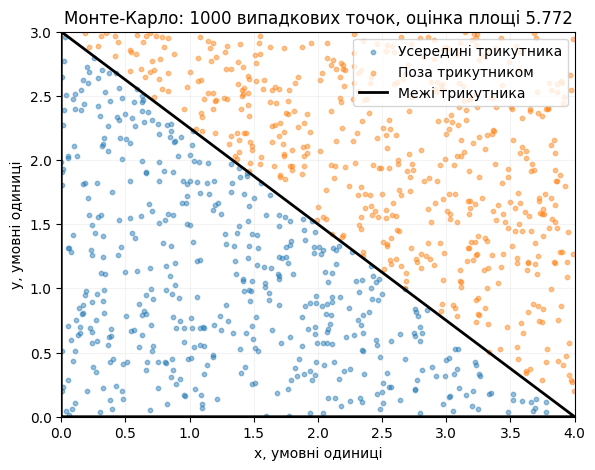

In [3]:
# Додаткова візуальна перевірка: точки всередині й поза трикутником
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x[inside], y[inside], s=10, alpha=0.45, label="Усередині трикутника")
ax.scatter(x[~inside], y[~inside], s=10, alpha=0.45, label="Поза трикутником")
ax.plot([0, 4, 0, 0], [0, 0, 3, 0], color="black", linewidth=2, label="Межі трикутника")
ax.set(xlim=(0, 4), ylim=(0, 3), xlabel="x, умовні одиниці", ylabel="y, умовні одиниці",
       title=f"Монте-Карло: {N} випадкових точок, оцінка площі {mc_estimate:.3f}")
ax.legend(loc="upper right", frameon=True)
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.15)
plt.show()

## Завдання 2. Порівняння з точним значенням

Обчислюємо абсолютну та відносну похибки для оцінки з попереднього завдання.

In [4]:
absolute_error = abs(mc_estimate - exact)
relative_error_pct = absolute_error / exact * 100

print(f"Точна площа: {exact:.4f} кв. од.")
print(f"Оцінка Монте-Карло: {mc_estimate:.4f} кв. од.")
print(f"Абсолютна похибка: {absolute_error:.4f} кв. од.")
print(f"Відносна похибка: {relative_error_pct:.2f}%")

Точна площа: 6.0000 кв. од.
Оцінка Монте-Карло: 5.7720 кв. од.
Абсолютна похибка: 0.2280 кв. од.
Відносна похибка: 3.80%


**Письмова оцінка.** При $N=1000$ отримано оцінку **5,772 кв. од.** проти точної площі **6 кв. од.** Абсолютна похибка дорівнює **0,228 кв. од.**, а відносна — **3,80%**. Це порівняно невелика, проте помітна похибка: за 1000 випадкових точок частка всередині трикутника може відхилятися від теоретичних 50%. Для такого числа випробувань це очікувано; під час подальшого збільшення $N$ похибка в середньому має зменшуватися.

## Завдання 3. Збіжність за кількістю випробувань

Для кожного $N$ з набору **100, 1000, 10 000, 100 000** виконуємо **200 незалежних повторів** та обчислюємо **середню абсолютну похибку**, щоб зменшити вплив випадковості одного запуску. `seed` фіксуємо один раз перед усіма повторами, як вимагає умова.

In [5]:
np.random.seed(variant)
repeats = 200
sample_sizes = [100, 1_000, 10_000, 100_000]
records = []

for n in sample_sizes:
    errors = []
    for _ in range(repeats):
        sim_x = np.random.uniform(0, 4, size=n)
        sim_y = np.random.uniform(0, 3, size=n)
        estimate = rectangle_area * ((sim_x / 4 + sim_y / 3) <= 1).mean()
        errors.append(abs(estimate - exact))
    records.append({
        "N": n,
        "Середня абсолютна похибка": np.mean(errors),
        "Відносна похибка, %": np.mean(errors) / exact * 100,
    })

error_table = pd.DataFrame(records)
display(error_table.round(6))

ratio_100_to_10000 = (error_table.loc[error_table["N"] == 100, "Середня абсолютна похибка"].iloc[0] /
                      error_table.loc[error_table["N"] == 10_000, "Середня абсолютна похибка"].iloc[0])
print(f"Похибка при збільшенні N від 100 до 10000 зменшилася у {ratio_100_to_10000:.2f} раза.")
print("Теоретичне зменшення за правилом 1/√N: у 10 разів.")

,N,Середня абсолютна похибка,"Відносна похибка, %"
0,100,0.489000,8.15000
1,1000,0.136680,2.27800
2,10000,0.046428,0.77380
3,100000,0.013576,0.22626


Похибка при збільшенні N від 100 до 10000 зменшилася у 10.53 раза.
Теоретичне зменшення за правилом 1/√N: у 10 разів.


**Письмовий висновок.** Середня абсолютна похибка зменшилася від **0,4890** при $N=100$ до **0,046428** при $N=10\,000$, тобто приблизно у **10,53 раза**. Теорія передбачає для збільшення кількості точок у 100 разів зменшення типової похибки приблизно у $\sqrt{100}=10$ разів; отримані значення добре узгоджуються з цією закономірністю. Для $N=100\,000$ середня абсолютна похибка вже дорівнює **0,013576**. Окремі випадкові оцінки можуть тимчасово ставати гіршими, але усереднення за 200 повторами чітко показує загальну тенденцію.

## Завдання 4. Графік похибки від N

Будуємо залежність середньої абсолютної похибки від кількості точок на логарифмічній осі X. Додатково наносимо довідкову криву $C/\sqrt{N}$, масштабовану за першим значенням, щоб порівняти форму спадання.

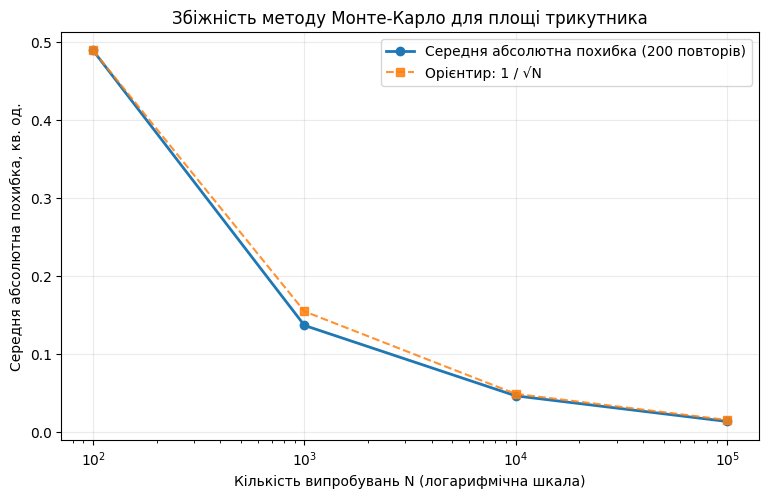

In [6]:
fig, ax = plt.subplots(figsize=(9, 5.3))
n_values = error_table["N"].to_numpy()
empirical_mae = error_table["Середня абсолютна похибка"].to_numpy()
reference = empirical_mae[0] * np.sqrt(n_values[0] / n_values)

ax.plot(n_values, empirical_mae, marker="o", linewidth=2, label="Середня абсолютна похибка (200 повторів)")
ax.plot(n_values, reference, linestyle="--", marker="s", alpha=0.85,
        label="Орієнтир: 1 / √N")
ax.set_xscale("log")
ax.set_xlabel("Кількість випробувань N (логарифмічна шкала)")
ax.set_ylabel("Середня абсолютна похибка, кв. од.")
ax.set_title("Збіжність методу Монте-Карло для площі трикутника")
ax.grid(True, alpha=0.25)
ax.legend()
plt.show()

**Письмовий висновок.** Крива похибки послідовно спадає зі зростанням $N$ та йде близько до орієнтира $1/\sqrt{N}$. Кожен крок збільшення $N$ приблизно в 10 разів у середньому зменшує похибку в кілька разів (порядку $\sqrt{10}\approx 3{,}16$), а не в 10 разів. Лінія не ідеально збігається з теоретичним орієнтиром, тому що 200 повторень — теж скінченна випадкова симуляція.

## Завдання 5. Зв'язок із законом великих чисел і ЦГТ

**Закон великих чисел (ЗВЧ).** Індикатор $I_i$ дорівнює 1, коли випадкова точка потрапляє в трикутник, і 0 інакше. Тому $E[I_i]=p=S/12=0{,}5$. За законом великих чисел частка $\frac1N\sum I_i$ наближається до $0{,}5$, а оцінка $12\cdot\overline I$ — до **6 кв. од.** зі зростанням кількості випробувань.

**Центральна гранична теорема (ЦГТ).** Вона описує розподіл похибок вибіркового середнього: для достатньо великого $N$ оцінка $\overline I$ має наближено нормальний вибірковий розподіл. Для нашого індикатора $p=0{,}5$ та $\sigma_I=\sqrt{p(1-p)}=0{,}5$, отже стандартна похибка **оцінки площі**:

$$SE(\widehat S_N)=12\cdot\frac{0{,}5}{\sqrt N}=\frac{6}{\sqrt N}.$$

Саме множник $1/\sqrt N$ пояснює швидкість збіжності з Завдання 3: у 100 разів більше точок — приблизно у 10 разів менша типова похибка, а не у 100 разів менша. ЗВЧ відповідає на питання **до якого значення наближається оцінка**, а ЦГТ і формула SE — **як коливається оцінка навколо цього значення**.

In [7]:
# Теоретична стандартна похибка нашої оцінки площі
se_values = 6 / np.sqrt(np.array(sample_sizes))
se_table = pd.DataFrame({
    "N": sample_sizes,
    "Теоретична SE площі": se_values,
    "Середня абсолютна похибка (симуляція)": empirical_mae,
})
display(se_table.round(6))

,N,Теоретична SE площі,Середня абсолютна похибка (симуляція)
0,100,0.600000,0.489000
1,1000,0.189737,0.136680
2,10000,0.060000,0.046428
3,100000,0.018974,0.013576


## Відповіді на контрольні питання

**1. Чому оцінка Монте-Карло є вибірковим середнім і що гарантує її збіжність?**  
Для кожної точки ми обчислюємо індикатор потрапляння в трикутник (0 або 1), а потім усереднюємо ці індикатори й множимо на сталу площу прямокутника 12. Закон великих чисел гарантує збіжність вибіркової частки до її математичного сподівання, тому оцінена площа наближається до точної площі 6.

**2. Чому учетверо більше випробувань зменшує типову похибку лише вдвічі?**  
Стандартна похибка вибіркового середнього дорівнює $\sigma/\sqrt N$, а для площі нашого трикутника — $6/\sqrt N$. Коли $N$ замінити на $4N$, у знаменнику з'являється $\sqrt{4N}=2\sqrt N$, тому SE стає вдвічі меншою, не в чотири рази. Йдеться про типову похибку, а не про гарантовану зміну помилки в одному випадковому прогоні.

**3. Чому частку точок усередині фігури множать на площу прямокутника?**  
Частка точок оцінює **ймовірність** потрапляння до фігури, тобто відношення $S_{\mathrm{трикутника}}/S_{\mathrm{прямокутника}}$, а не саму площу. У нашому випадку приблизно $0{,}5$ — це частка, а фізична площа дорівнює $0{,}5\cdot12=6$ квадратних одиниць. Без множення результат помилково дорівнював би приблизно $0{,}5$.

**4. Чому в задачах на сподівання для кількох кидків кубика потрібен `axis=1`?**  
Це загальне контрольне питання для інших варіантів, але принцип такий: якщо кожен рядок матриці є окремим випробуванням, `.min(axis=1)` або `.max(axis=1)` знаходить одне значення для **кожного рядка**; виходить масив із $N$ результатів, який можна усереднити. Без `axis` функція шукає один глобальний мінімум або максимум усієї матриці, а не $N$ результатів. Для нашого варіанта з площею трикутника замість цього використовується булевий індикатор та його `.mean()`.

## Загальний висновок

Для **варіанта №5 (Дніпро)** методом Монте-Карло визначено площу трикутника з вершинами $(0;0)$, $(4;0)$, $(0;3)$. При $N=1000$ отримано **5,772 кв. од.**, що відрізняється від точної площі **6 кв. од.** на **3,80%**. Проведено по 200 повторних симуляцій для чотирьох обсягів вибірки, складено таблицю й графік збіжності. Зменшення середньої абсолютної похибки приблизно за законом $1/\sqrt{N}$ узгоджується із законом великих чисел, ЦГТ та формулою стандартної похибки.

**Усі завдання 1–5 та контрольні питання виконано.**